In [41]:
#imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, GridSearchCV,cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#Set random seed to the meaning of life
np.random.seed(42)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [42]:
#Data Download
dataCandidates = [os.path.join("data","insurance.csv"), "insurance.csv"]

csv_path = next((p for p in dataCandidates if os.path.isfile(p)), None)

if csv_path is None:
    try:
        import kagglehub
        dataset_path = kagglehub.dataset_download(
            "willianoliveiragibin/healthcare-insurance"
        )
        csv_path = os.path.join(dataset_path, "insurance.csv")
    except Exception as e:
        raise FileNotFoundError(
            str(e)
        )
df = pd.read_csv(csv_path)
print("Original Shape: ", df.shape)
display(df.head())
display(df.info())

Original Shape:  (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


None

In [43]:
#Check Data Quality and Process
print("Missing vals: ")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Summary:")
display(df.describe(include="all").T)

df = df.drop_duplicates().reset_index(drop = True)

requiredCols = ["age", "sex", "bmi", "children", "smoker", "region","charges"]
missingCols = [c for c in requiredCols if c not in df.columns]
if missingCols:
    raise ValueError(f"Missing columns: {missingCols}")

if(df[requiredCols].isnull().values.any()):
    raise ValueError(f"Missing values: {df[requiredCols].isnull().values.any()}")

print("New shape: ", df.shape)
print("Charges Summary: ")
display(df["charges"].describe())

Missing vals: 


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"1,338.0000",NaN,NaN,NaN,39.2070,14.0500,18.0000,27.0000,39.0000,51.0000,64.0000
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,"1,338.0000",NaN,NaN,NaN,30.6634,6.0982,15.9600,26.2963,30.4000,34.6938,53.1300
children,"1,338.0000",NaN,NaN,NaN,1.0949,1.2055,0.0000,0.0000,1.0000,2.0000,5.0000
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,"1,338.0000",NaN,NaN,NaN,"13,270.4223","12,110.0112","1,121.8739","4,740.2872","9,382.0330","16,639.9125","63,770.4280"


New shape:  (1337, 7)
Charges Summary: 


count    1,337.0000
mean    13,279.1215
std     12,110.3597
min      1,121.8739
25%      4,746.3440
50%      9,386.1613
75%     16,657.7175
max     63,770.4280
Name: charges, dtype: float64

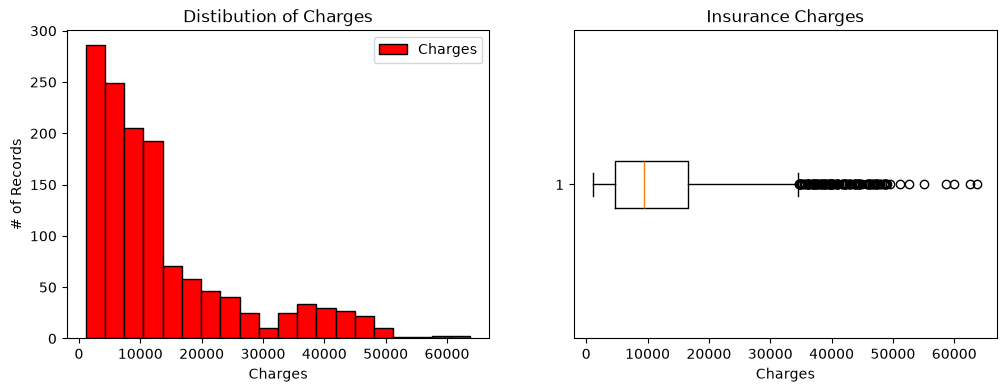

In [44]:
#Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["charges"], bins=20, edgecolor = "black", color="red", label="Charges")
axes[0].set_xlabel("Charges")
axes[0].set_ylabel("# of Records")
axes[0].legend(loc="upper right")
axes[0].set_title("Distibution of Charges")

axes[1].boxplot(df["charges"], orientation="horizontal")
axes[1].set_xlabel("Charges")
axes[1].set_title("Insurance Charges")
#plt.tight_layout()
plt.show()

In [45]:
#Get the predictors, the target, and assign the 80/20 split so the split is the same across all models.

target = "charges"
numericFeatures = ["age", "bmi", "children"]
categorialFeatures = ["sex", "smoker", "region"]
featureCols = numericFeatures  + categorialFeatures

X = df[featureCols].copy()
Y = df[target].astype(float).copy()

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

print("Training Rows: ", len(X_train))
print("Testing Rows: ", len(X_test))
print("Training Frac: ", len(X_train)/len(X))


Training Rows:  1069
Testing Rows:  268
Training Frac:  0.7995512341062079


In [46]:
#Preprocessing and evaluations

def make_preprocessor():
    return ColumnTransformer(
        transformers=[("numeric", StandardScaler(), numericFeatures),("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorialFeatures)
        ],
        remainder="drop"
    )

def regression_evaluations(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return{
        "mse": mse,
        "r2": r2_score(y_real, y_pred),
        "mae": mean_absolute_error(y_real, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_real, y_pred)),
    }

def evaluate_predictions(model, y_real, y_pred):
    row = {"Model": model}
    row.update(regression_evaluations(y_real, y_pred))
    return row

def plot_actual_predicted(y_real, y_pred, title):
    low = min(float(np.min(y_real)), float(np.min(y_pred)))
    high = max(float(np.max(y_real)), float(np.max(y_pred)))
    plt.figure(figsize = (10, 10))
    plt.scatter(y_real, y_pred, color = "blue", alpha = 0.5)
    plt.plot([low, high], [low, high], "r--", label = "Perfect Prediction")
    plt.xlabel("Actual chargers ($)")
    plt.ylabel("Predicted chargers ($)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_residuals(y_real, y_pred, title):
    resids = np.asarray(y_real) - np.asarray(y_pred)
    plt.figure(figsize = (8, 5))
    plt.scatter(y_pred, resids, color = "blue", alpha = 0.5)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predicted charges ($)")
    plt.ylabel("Residual (actual - predicted) ($)")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [51]:
#Experiment 1: Linear Regression and Batch Gradient Descent

linearPreprocessor = make_preprocessor()
Xtrain = linearPreprocessor.fit_transform(X_train)
Xtest = linearPreprocessor.transform(X_test)

#Convert to readable matrices for sklearn
Xtrain = Xtrain.toarray() if hasattr(Xtrain, "toarray") else np.asarray(Xtrain)
Xtest = Xtest.toarray() if hasattr(Xtest, "toarray") else np.asarray(Xtest)

#Add an intercept column.
Xtrain_b = np.column_stack([np.ones(Xtrain.shape[0]), Xtrain])
Xtest_b = np.column_stack([np.ones(Xtest.shape[0]), Xtest])

#Standardize Y
YMean = Y_train.mean()
YStd = Y_train.std()
YtrainScaled = (Y_train.to_numpy() - YMean) / YStd

#Least Squares

olsWeights, residuals, rank, singularVals = np.linalg.lstsq(Xtrain_b, YtrainScaled, rcond=None)

def batch_gradient_descent(X, Y, learningRate = 0.01, iterations = 10000):
    m,n = X.shape
    weights = np.zeros(n)
    costs = []

    for _ in range(iterations):
        errors = X @ weights - Y
        gradient = (X.T @ errors) / m
        weights -= learningRate * gradient

        updatedErrors = X @ weights - Y
        cost = np.sum(updatedErrors ** 2) / (2*m)
        costs.append(cost)

    return weights, costs

gradientWeights, gradientCosts = batch_gradient_descent(Xtrain_b, YtrainScaled)

print("Max coefficient difference (ordinary least squares vs gradient descent): ", np.max(np.abs(olsWeights - gradientWeights)))
print("Final GD cost: ", gradientCosts[-1])

Max coefficient difference (ordinary least squares vs gradient descent):  0.0006165299030811006
Final GD cost:  0.13492081263652805


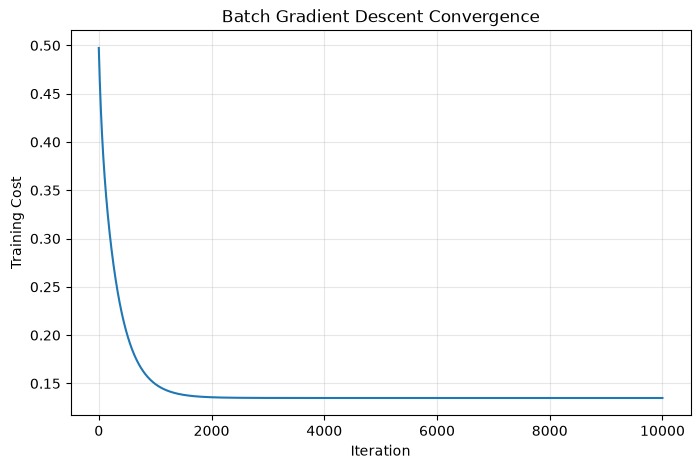

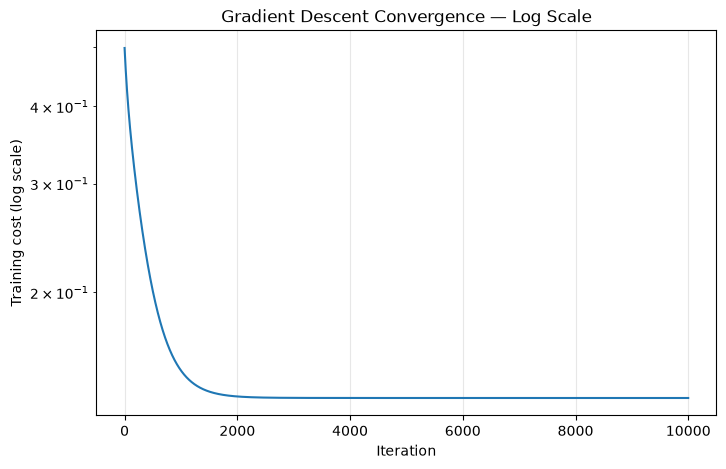

In [52]:
#Visualizations

plt.figure(figsize = (8,5))
plt.plot(gradientCosts)
plt.xlabel("Iteration")
plt.ylabel("Training Cost")
plt.title("Batch Gradient Descent Convergence")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.semilogy(gradientCosts)
plt.xlabel("Iteration")
plt.ylabel("Training cost (log scale)")
plt.title("Gradient Descent Convergence — Log Scale")
plt.grid(alpha=0.3)
plt.show()

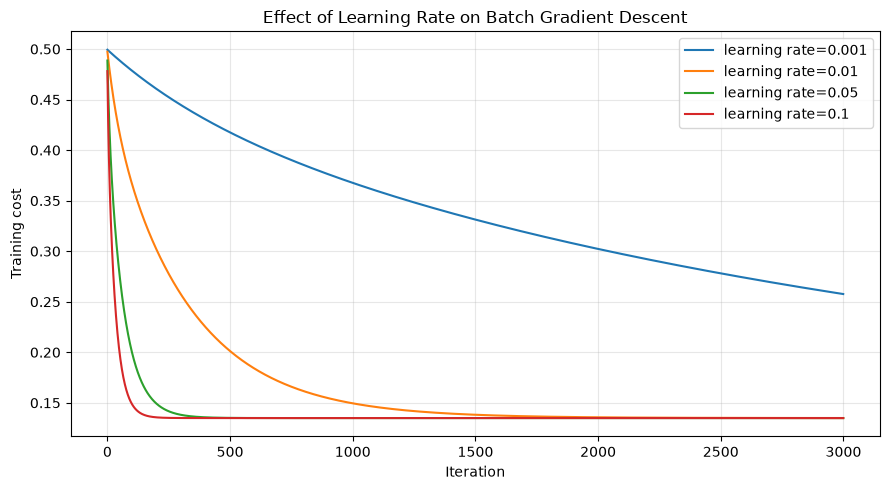

In [54]:
#Learning Rate/Iteration Count Effects & Visualization

learningRates = [0.001, 0.01, 0.05, 0.1]
plt.figure(figsize=(9, 5))

for lr in learningRates:
    _, costs = batch_gradient_descent(Xtrain_b, YtrainScaled, learningRate=lr, iterations=3000)
    plt.plot(costs, label=f"learning rate={lr}")

plt.xlabel("Iteration")
plt.ylabel("Training cost")
plt.title("Effect of Learning Rate on Batch Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Model,mse,r2,mae,rmse
0,Least Squares,"35,478,020.6752",0.8069,"4,177.0456","5,956.3429"
1,Gradient Descent,"35,476,333.7537",0.8069,"4,177.1237","5,956.2013"


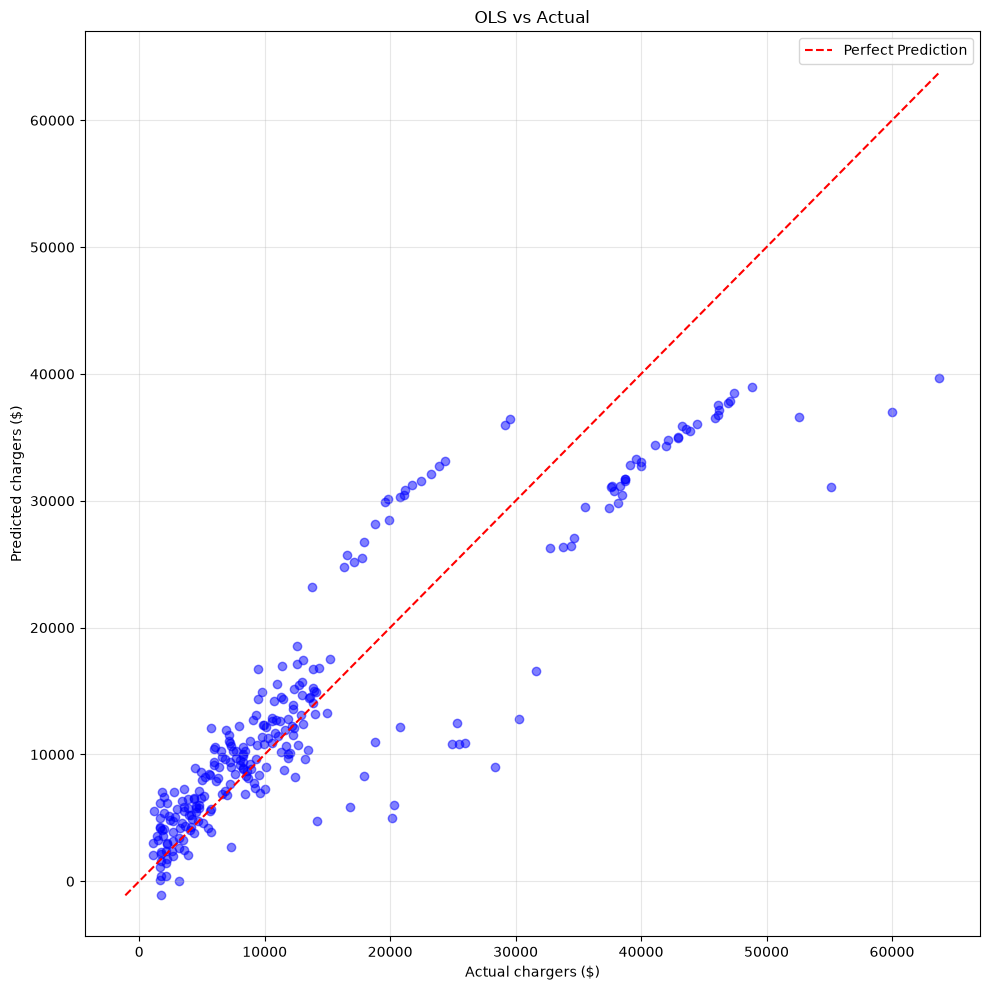

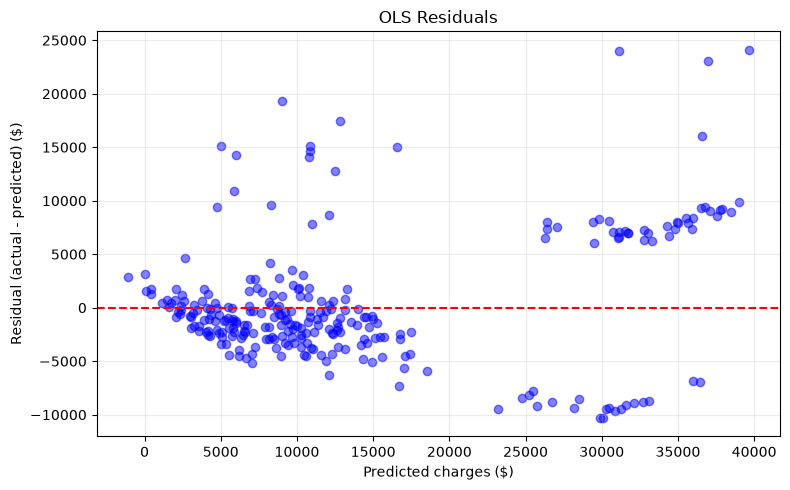

In [56]:
#OLS vs Gradient Descent on Test Set

def predictTarget(X, weights):
    prediction = X @ weights
    return prediction * YStd + YMean

OLSPrediction = predictTarget(Xtest_b, olsWeights)
gradientPrediction = predictTarget(Xtest_b, gradientWeights)

experimentOneResults = pd.DataFrame([evaluate_predictions("Least Squares", Y_test, OLSPrediction),
evaluate_predictions("Gradient Descent", Y_test, gradientPrediction)])
display(experimentOneResults)

plot_actual_predicted(Y_test, OLSPrediction, "OLS vs Actual")
plot_residuals(Y_Ftest, OLSPrediction, "OLS Residuals")

In [57]:
def ridge_gradient_descent(X, Y, alpha, learning_rate = 0.01, iterations = 10000):
    m,n = X.shape
    weights = np.zeros(n)
    costs = []

    for _ in range(iterations):
        errors = X @ weights - Y
        gradient = (X.T @ errors) / m
        gradient[1:] += (alpha/m) * weights[1:]
        weights -= learning_rate * gradient
        updatedErrors = X @ weights - Y
        cost = np.sum(updatedErrors ** 2) / (2*m)
        cost += (alpha / (2*m)) * np.sum(weights[1:] ** 2)
        costs.append(cost)

    return weights, costs

ridgeAlphas = [0.1, 1, 10, 100, 1000, 5000, 10000]
ridgeModels = {}
ridgeRows = []
ridgePredictions = {}

for alpha in ridgeAlphas:
    w, costs = ridge_gradient_descent(Xtrain_b, YtrainScaled, alpha=alpha)
    prediction = predictTarget(Xtest_b, w)
    ridgeModels[alpha] = prediction
    row = evaluate_predictions(f"Ridge alpha of {alpha}: ", Y_test, prediction)
    row["alpha"] = alpha
    ridgeRows.append(row)

ridgeResults_df = pd.DataFrame(ridgeRows)
display(ridgeResults_df)

,Model,mse,r2,mae,rmse,alpha
0,Ridge alpha of 0.1:,"35,494,649.5309",0.8068,"4,178.8173","5,957.7386",0.1000
1,Ridge alpha of 1:,"35,661,550.9673",0.8059,"4,193.9673","5,971.7293",1.0000
2,Ridge alpha of 10:,"37,506,694.3780",0.7959,"4,344.1954","6,124.2709",10.0000
3,Ridge alpha of 100:,"60,358,512.0448",0.6715,"5,521.8415","7,769.0741",100.0000
4,Ridge alpha of 1000:,"137,359,111.1257",0.2525,"8,640.2956","11,720.0303","1,000.0000"
5,Ridge alpha of 5000:,"170,679,707.8545",0.0712,"9,523.9507","13,064.4444","5,000.0000"
6,Ridge alpha of 10000:,"177,355,980.5873",0.0348,"9,677.9507","13,317.5065","10,000.0000"
